# Module 08 Lab - The Bias-Variance Tradeoff
## Danh Nguyen — Degree 15 Model (Overfitting)

**My assigned task:** Build and plot the degree 15 model; explain why it overfits.

## Setup
Same synthetic sine-wave dataset as the group notebook (Part 2).

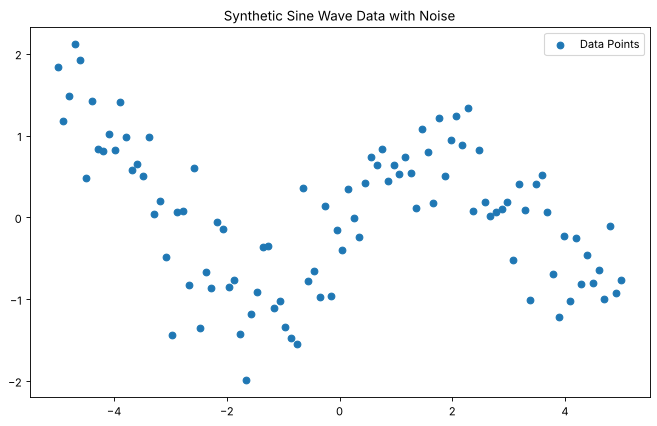

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import learning_curve

# Generate some synthetic data
np.random.seed(0)
X = np.linspace(-5, 5, 100)
y = np.sin(X) + np.random.normal(0, 0.5, 100)
X = X[:, np.newaxis]

# Plot the data to see the underlying sine wave pattern
plt.figure(figsize=(10, 6))
plt.scatter(X, y, label='Data Points')
plt.title('Synthetic Sine Wave Data with Noise')
plt.legend()
plt.show()

## Degree 15 Model

Degree 15 - Training MSE:         0.205
Degree 15 - Cross-validation MSE: 1.027


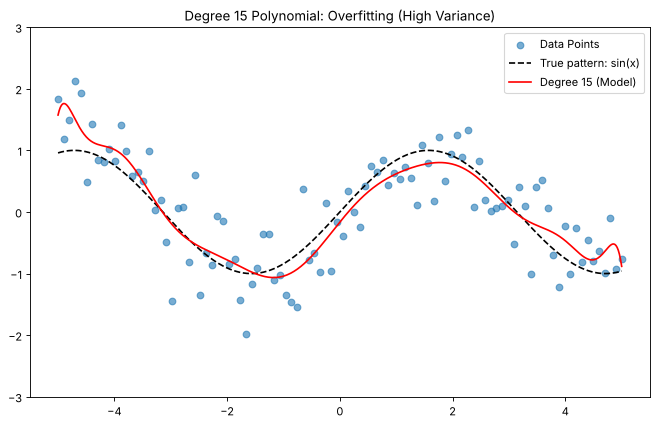

In [2]:
# ---- Danh: Degree 15 polynomial model (overfitting) ----
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import mean_squared_error

degree = 15

# 1. Pipeline: polynomial features -> scale them -> linear regression
#    (x**15 reaches ~30 billion at x = 5, so scaling keeps the math numerically stable)
model_15 = make_pipeline(PolynomialFeatures(degree), StandardScaler(), LinearRegression())

# 2. Train the model
model_15.fit(X, y)

# 3. Measure error on the training data vs. on unseen data (5-fold cross-validation)
train_mse_15 = mean_squared_error(y, model_15.predict(X))
kfold = KFold(n_splits=5, shuffle=True, random_state=0)
cv_mse_15 = -cross_val_score(model_15, X, y, cv=kfold,
                             scoring="neg_mean_squared_error").mean()
print(f"Degree {degree} - Training MSE:         {train_mse_15:.3f}")
print(f"Degree {degree} - Cross-validation MSE: {cv_mse_15:.3f}")

# 4. Plot predictions on a fine grid so the wiggles between points are visible
X_plot = np.linspace(-5, 5, 500)[:, np.newaxis]
plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.6, label='Data Points')
plt.plot(X_plot, np.sin(X_plot), 'k--', label='True pattern: sin(x)')
plt.plot(X_plot, model_15.predict(X_plot), color='red', label=f'Degree {degree} (Model)')
plt.title(f'Degree {degree} Polynomial: Overfitting (High Variance)')
plt.ylim(-3, 3)
plt.legend()
plt.show()

## Why the Degree 15 Model Overfits

**Why the degree 15 model overfits:** A degree 15 polynomial is so flexible that it bends to chase individual noisy points instead of following the true sine-wave pattern. It has the **lowest training error** of the three models (MSE ≈ 0.21, vs. 0.32 for degree 4 and 0.71 for degree 1). But its error on unseen data in cross-validation is the **highest** (≈ 1.03, vs. 0.39 for degree 4). That large gap between training and validation performance is the signature of **high variance**: the model memorized the noise in this training set, like a student who memorizes answers but fails the exam. The plot shows it most clearly at the edges (x ≈ −5 and x ≈ 5), where the red curve jerks up and down to hit single points and drifts away from the dashed true pattern. Degree 4 is the better choice because it captures the real signal and ignores the noise.